In [8]:
!pip install -q "rfdetr[train,loggers]>=1.4.0" roboflow "supervision==0.29.1"



[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Looking in indexes: https://download.pytorch.org/whl/cu121
     ---------------------------------------- 0.0/4.1 MB ? eta -:--:--
     ------- -------------------------------- 0.8/4.1 MB 5.6 MB/s eta 0:00:01
     ---------------------- ----------------- 2.4/4.1 MB 7.5 MB/s eta 0:00:01
     -------------------------------------- - 3.9/4.1 MB 7.8 MB/s eta 0:00:01
     ---------------------------------------- 4.1/4.1 MB 7.3 MB/s  0:00:00
INFO: pip is looking at multiple versions of torchaudio to determine which version is compatible with other requirements. This could take a while.
     ---------------------------------------- 0.0/4.1 MB ? eta -:--:--
     ----------------- ---------------------- 1.8/4.1 MB 8.4 MB/s eta 0:00:01
     -------------------------------- ------- 3.4/4.1 MB 8.8 MB/s eta 0:00:01
     ---------------------------------------- 4.1/4.1 MB 8.3 MB/s  0:00:00
     ---------------------------------------- 0.0/4.1 MB ? eta -:--:--
     --------------- --------------------

  You can safely remove it manually.
  You can safely remove it manually.

[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import torch

# Check GPU availability
if torch.cuda.is_available():
    print(f"GPU detected: {torch.cuda.get_device_name(0)}")
    print(f"GPU count: {torch.cuda.device_count()}")
else:
    print("GPU not detected. PyTorch will execute on CPU!")

print(f"PyTorch version: {torch.__version__}")


GPU terdeteksi: NVIDIA GeForce RTX 4050 Laptop GPU
Jumlah GPU: 1
Versi PyTorch: 2.13.0+cu126


In [5]:
from rfdetr import RFDETRNano

model = RFDETRNano()

model.train(dataset_dir='../dataset_coco',
            epochs=1,
            batch_size=1,
            grad_accum_steps=2,
            early_stopping=True,
            early_stopping_patience=1,
            device="cuda")

Val (Epoch 1/1) — Overall Metrics                
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃           mAP            ┃  mAR   ┃         F1 sweep         ┃
┡━━━━━━━━┯━━━━━━━━┯━━━━━━━━╇━━━━━━━━╇━━━━━━━━┯━━━━━━━━┯━━━━━━━━┩
│ 50:95  │   50   │   75   │  @500  │   F1   │  Prec  │ Recall │
├────────┼────────┼────────┼────────┼────────┼────────┼────────┤
│ 0.0313 │ 0.1082 │ 0.0085 │ 0.1096 │ 0.2163 │ 0.2571 │ 0.1868 │
└────────┴────────┴────────┴────────┴────────┴────────┴────────┘
            Val (Epoch 1/1) — Per-class Metrics            
┏━━━━━━━┳━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━┓
┃ Class ┃ AP 50:95 ┃     AR ┃     F1 ┃ Precision ┃ Recall ┃
┡━━━━━━━╇━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━┩
│ acne  │   0.0313 │ 0.1096 │ 0.2163 │    0.2571 │ 0.1868 │
└───────┴──────────┴────────┴────────┴───────────┴────────┘

Metric __rfdetr_effective_map__ improved. New best score: 0.037


[2026-07-28 14:20:49] [INFO] rf-detr - Best regular checkpoint saved to C:\Users\wifqo\OneDrive\Dokumen\PROJECTS\rfdetr-acne-detection-3\output\checkpoint_best_regular.pth (epoch 0, monitor=val/mAP_50_95, value=0.0312697)
[2026-07-28 14:20:50] [INFO] rf-detr - Best EMA mAP improved to 0.0373 (epoch 0)


`Trainer.fit` stopped: `max_epochs=1` reached.


[2026-07-28 14:20:59] [INFO] rf-detr - Best total checkpoint saved from EMA (regular=0.0313, ema=0.0373)


## Inference

In [1]:
import os
from rfdetr import RFDETRLarge

# Absolute path to best model checkpoint in local folder
model_path = os.path.abspath("best_rfdetr_acne.pth")

# Initialize model with pretrained weights and optimize for inference
model = RFDETRLarge(pretrain_weights=model_path)
model.optimize_for_inference()


C:\Users\wifqo\OneDrive\Dokumen\PROJECTS\rfdetr-acne-detection-3\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\wifqo\OneDrive\Dokumen\PROJECTS\rfdetr-acne-detection-3\.venv\Lib\site-packages\rfdetr\models\weights.py:258: FutureWarning: target=True is deprecated since `v0.8`; use `TargetMode.ARGS_REMAP` instead. Will be removed in `v1.0`.
  @deprecated(target=True, args_mapping={"train_config": None}, deprecated_in="1.7.0", remove_in="1.9.0", num_warns=-1)
[2026-07-29 13:10:47] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-07-29 13:10:47] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone we

In [2]:
import supervision as sv

ds = sv.DetectionDataset.from_coco(
    images_directory_path="../dataset_coco/test",
    annotations_path="../dataset_coco/test/_annotations.coco.json",
)

In [3]:
import supervision as sv
from tqdm import tqdm
from supervision.metrics import MeanAveragePrecision
from PIL import Image

targets = []
predictions = []

for path, image, annotations in tqdm(ds):
    image = Image.open(path)
    detections = model.predict(image, threshold=0)

    targets.append(annotations)
    predictions.append(detections)


100%|██████████| 180/180 [01:23<00:00,  2.16it/s]


In [4]:
map_metric = MeanAveragePrecision()
map_result = map_metric.update(predictions, targets).compute()
print(map_result)

Average Precision (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.134
Average Precision (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.377
Average Precision (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.062
Average Precision (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.040
Average Precision (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.161
Average Precision (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.195


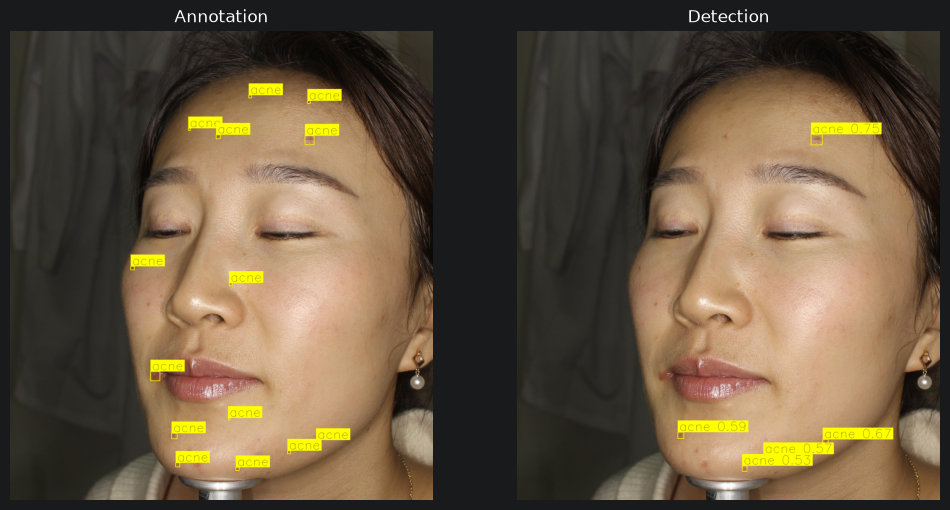

In [10]:
from rfdetr import RFDETRBase
import supervision as sv
from PIL import Image

path, image, annotations = ds[70]
image = Image.open(path)

detections = model.predict(image, threshold=0.5)

text_scale = sv.calculate_optimal_text_scale(resolution_wh=image.size)
thickness = sv.calculate_optimal_line_thickness(resolution_wh=image.size)
color = sv.ColorPalette.from_hex([
    "#ffff00", "#ff9b00", "#ff66ff", "#3399ff", "#ff66b2", "#ff8080",
    "#b266ff", "#9999ff", "#66ffff", "#33ff99", "#66ff66", "#99ff00"
])

bbox_annotator = sv.BoxAnnotator(color=color,thickness=thickness)
label_annotator = sv.LabelAnnotator(
    color=color,
    text_color=sv.Color.BLACK,
    text_scale=text_scale)

annotations_labels = [
    f"{ds.classes[class_id]}"
    for class_id
    in annotations.class_id
]

detections_labels = [
    f"{ds.classes[class_id]} {confidence:.2f}"
    for class_id, confidence
    in zip(detections.class_id, detections.confidence)
]

annotation_image = image.copy()
annotation_image = bbox_annotator.annotate(annotation_image, annotations)
annotation_image = label_annotator.annotate(annotation_image, annotations, annotations_labels)

detections_image = image.copy()
detections_image = bbox_annotator.annotate(detections_image, detections)
detections_image = label_annotator.annotate(detections_image, detections, detections_labels)

sv.plot_images_grid(images=[annotation_image, detections_image], grid_size=(1, 2), titles=["Annotation", "Detection"])

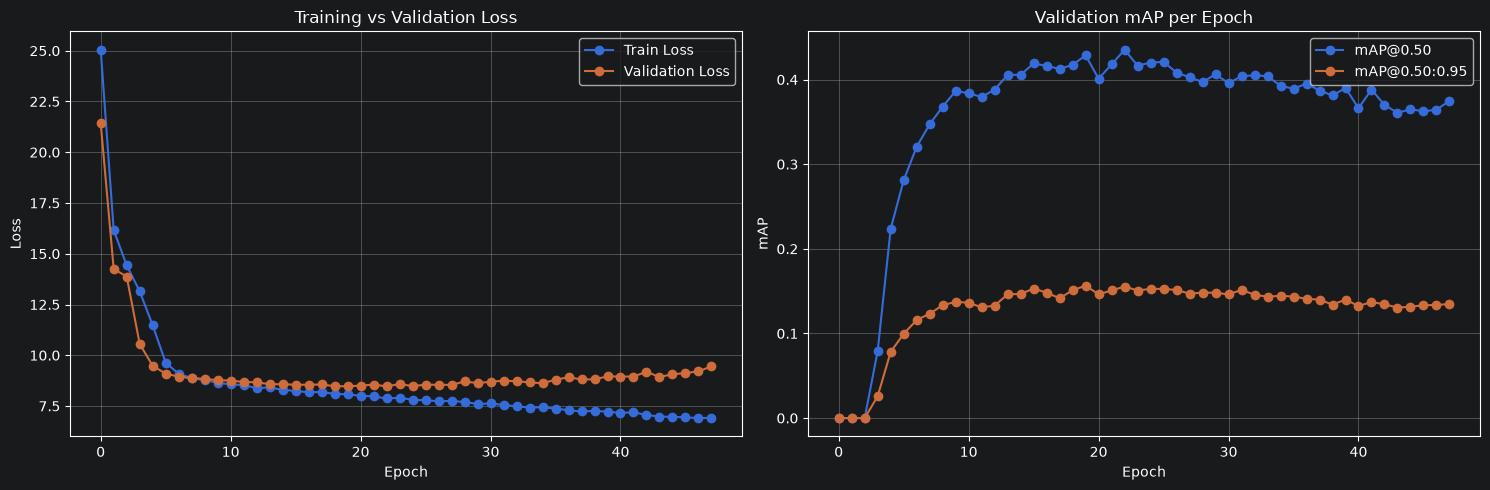

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# Load evaluation metrics log
df = pd.read_csv('metrics_acne.csv')
val_df = df.groupby('epoch').mean().reset_index()

plt.figure(figsize=(15, 5))

# Plot 1: Train & Val Loss
plt.subplot(1, 2, 1)
plt.plot(val_df['epoch'], val_df['train/loss'], label='Train Loss', marker='o')
plt.plot(val_df['epoch'], val_df['val/loss'], label='Validation Loss', marker='o')
plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot 2: mAP (Mean Average Precision)
plt.subplot(1, 2, 2)
plt.plot(val_df['epoch'], val_df['val/mAP_50'], label='mAP@0.50', marker='o')
plt.plot(val_df['epoch'], val_df['val/mAP_50_95'], label='mAP@0.50:0.95', marker='o')
plt.title('Validation mAP per Epoch')
plt.xlabel('Epoch')
plt.ylabel('mAP')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


=== Total Training and Validation Loss Per Epoch ===
 epoch  train/loss  val/loss
     0   25.046860 21.429111
     1   16.165295 14.249116
     2   14.428923 13.877365
     3   13.152265 10.561903
     4   11.473823  9.478488
     5    9.636464  9.096919
     6    9.085819  8.943839
     7    8.875752  8.870606
     8    8.772348  8.842421
     9    8.652404  8.771553
    10    8.560677  8.755619
    11    8.535128  8.682149
    12    8.376873  8.670141
    13    8.418104  8.572990
    14    8.294187  8.574830
    15    8.242907  8.548679
    16    8.175807  8.548311
    17    8.190317  8.561790
    18    8.094047  8.475909
    19    8.076616  8.473165
    20    8.003432  8.504089
    21    7.977717  8.558290
    22    7.870977  8.466271
    23    7.906486  8.583963
    24    7.810987  8.480130
    25    7.778162  8.551667
    26    7.739985  8.546142
    27    7.746053  8.540112
    28    7.698656  8.708610
    29    7.601129  8.629666
    30    7.624796  8.694875
    31    7.550969 

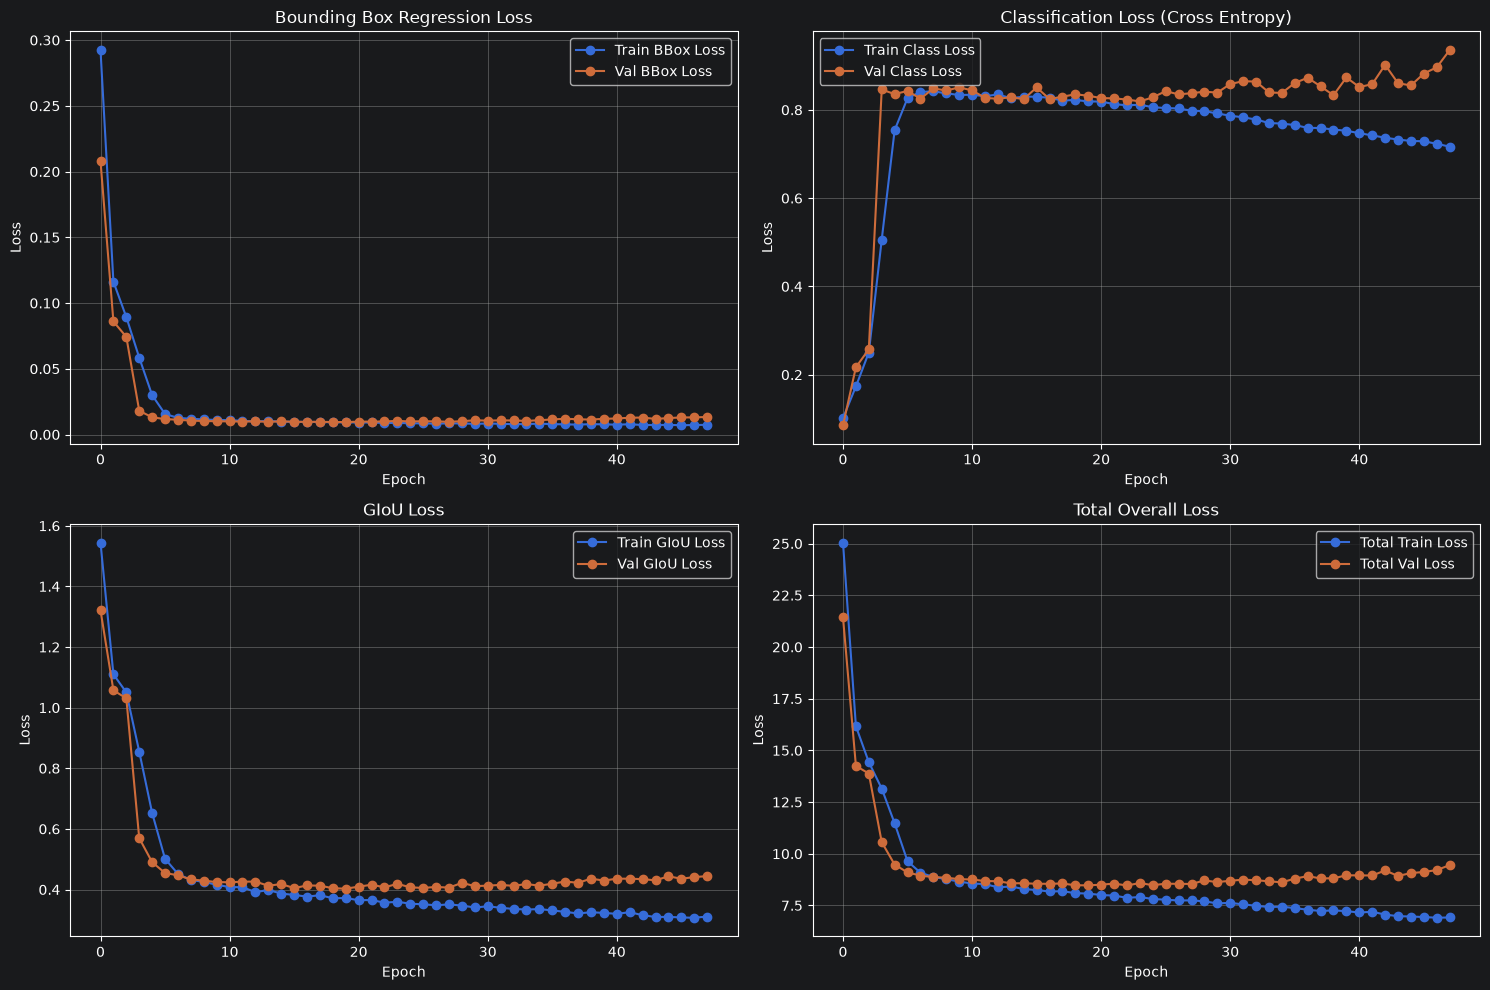

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('metrics_acne.csv')
# Aggregate training and validation metrics by epoch
val_df = df.groupby('epoch').mean().reset_index()

# 1. Report total training and validation loss per epoch
print('=== Total Training and Validation Loss Per Epoch ===')
print(val_df[['epoch', 'train/loss', 'val/loss']].to_string(index=False))
print('\n')

# 2. Calculate summary statistics
epoch_1_train = val_df['train/loss'].iloc[0]
epoch_1_val = val_df['val/loss'].iloc[0]

lowest_train_loss = val_df['train/loss'].min()
lowest_val_loss = val_df['val/loss'].min()

best_metric_idx = val_df['val/mAP_50_95'].idxmax()
best_metric_epoch = val_df['epoch'].iloc[best_metric_idx]
val_loss_at_best_metric = val_df['val/loss'].iloc[best_metric_idx]

final_train_loss = val_df['train/loss'].iloc[-1]
final_val_loss = val_df['val/loss'].iloc[-1]
final_loss_gap = abs(final_train_loss - final_val_loss)

print('=== Loss Reporting Summary ===')
print(f'Epoch-1 Loss: Train = {epoch_1_train:.4f}, Val = {epoch_1_val:.4f}')
print(f'Lowest Train Loss: {lowest_train_loss:.4f}')
print(f'Lowest Validation Loss: {lowest_val_loss:.4f}')
print(f'Validation Loss at Best-Metric Epoch (Epoch {best_metric_epoch}): {val_loss_at_best_metric:.4f}')
print(f'Final Loss: Train = {final_train_loss:.4f}, Val = {final_val_loss:.4f}')
print(f'Train-Validation Loss Gap (Final): {final_loss_gap:.4f}')
print('\n')

# 3. Plot individual loss components
print('Rendering loss component curves...')
plt.figure(figsize=(15, 10))

# Subplot 1: Bounding Box Regression Loss
plt.subplot(2, 2, 1)
plt.plot(val_df['epoch'], val_df['train/loss_bbox'], label='Train BBox Loss', marker='o')
plt.plot(val_df['epoch'], val_df['val/loss_bbox'], label='Val BBox Loss', marker='o')
plt.title('Bounding Box Regression Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Subplot 2: Classification Loss
plt.subplot(2, 2, 2)
plt.plot(val_df['epoch'], val_df['train/loss_ce'], label='Train Class Loss', marker='o')
plt.plot(val_df['epoch'], val_df['val/loss_ce'], label='Val Class Loss', marker='o')
plt.title('Classification Loss (Cross Entropy)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Subplot 3: GIoU Loss
plt.subplot(2, 2, 3)
plt.plot(val_df['epoch'], val_df['train/loss_giou'], label='Train GIoU Loss', marker='o')
plt.plot(val_df['epoch'], val_df['val/loss_giou'], label='Val GIoU Loss', marker='o')
plt.title('GIoU Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Subplot 4: Total Loss
plt.subplot(2, 2, 4)
plt.plot(val_df['epoch'], val_df['train/loss'], label='Total Train Loss', marker='o')
plt.plot(val_df['epoch'], val_df['val/loss'], label='Total Val Loss', marker='o')
plt.title('Total Overall Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
